# D09. Референсы для W4-квантования

Сколько качества теряем после простого округления и сколько возвращают GPTQ и AWQ? Начал с трёх небольших языковых моделей, чтобы дальше сравнивать свои идеи с сильным контролем для каждой модели.

**Результат.** AWQ дал меньшую PPL на SmolLM2-135M, GPTQ — на Pythia-160M и OPT-125M. После этого в поиске использовал соответствующий сильный референс.

[Протокол дня](README.md) · [Дальше: поиск форматов](../D10/experiments.ipynb)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

day = Path("quantization/research/D09")
for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / day / "results").is_dir():
        results = directory / day / "results"
        break
else:
    raise FileNotFoundError(f"Не найдены CSV в {day}/results")

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 120})

## Основной прогон

Квантуются веса Linear внутри блоков Transformer, по 4 бита и с группами по 128 весов. Для GPTQ и AWQ беру среднюю PPL по трём частично перекрывающимся калибровочным подмножествам из train, по 16 384 токена. FP и RTN здесь имеют по одному измерению на модель. Оценка идёт по полной WikiText-2 raw validation с окном 1024 и шагом 512.

method,FP,RTN,GPTQ,AWQ
model,,,,
OPT-125M,27.0983,29.5852,28.3184,28.5295
Pythia-160M,26.7249,45.4585,34.2459,35.5741
SmolLM2-135M,15.6305,21.5816,19.5822,18.0526


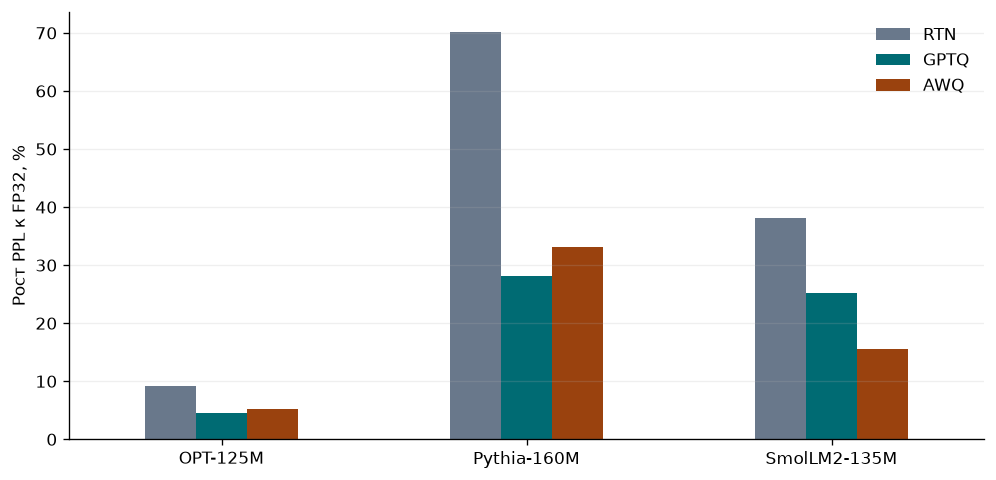

In [2]:
runs = pd.read_csv(results / "validation.csv")
runs["model"] = runs["model"].str.split("/").str[-1].replace(
    {"opt-125m": "OPT-125M", "pythia-160m": "Pythia-160M"})
methods = ["FP", "RTN", "GPTQ", "AWQ"]
w4 = runs[runs["method"].isin(methods)]
counts = w4.groupby(["model", "method"]).size().unstack()
assert counts[methods].eq(pd.Series(dict(FP=1, RTN=1, GPTQ=3, AWQ=3))).all().all()
scores = w4.pivot_table(index="model", columns="method", values="ppl")[methods]
display(scores.round(4))

rise = 100 * (scores[methods[1:]].div(scores["FP"], axis=0) - 1)
ax = rise.plot.bar(figsize=(8.4, 4.1), rot=0, color=["#69788b", "#006b73", "#9a420e"])
ax.set(xlabel="", ylabel="Рост PPL к FP32, %")
ax.legend(title=None, frameon=False)
ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

У Pythia простой RTN даёт самый большой рост PPL к своему FP32. GPTQ снижает PPL с **45,4585 до 34,2459**, при FP32 **26,7249**. На OPT разница между W4-вариантами меньше. На графике сравнение нормировано внутри каждой модели, поскольку абсолютная PPL зависит и от токенизатора.

## Отдельный режим W8A8

Проверил SmoothQuant на входах Linear. Сглаживание переносит часть динамического диапазона из активаций в веса. Для Smol завершены три калибровки, для других моделей — две. Здесь другой битовый бюджет.

In [3]:
smooth = runs[runs["method"].eq("SmoothQuant")].groupby("model")["ppl"].agg(["mean", "size"])
smooth["W8A8"] = runs[runs["method"].eq("unsmoothed_W8A8")].set_index("model")["ppl"]
display(smooth[["W8A8", "mean", "size"]].rename(
    columns={"mean": "SmoothQuant", "size": "Калибровок"}).round(4))
print(f"Завершено {len(runs)} из 54 запланированных оценок")

,W8A8,SmoothQuant,Калибровок
model,,,
OPT-125M,27.4004,27.2302,2
Pythia-160M,27.5705,27.3104,2
SmolLM2-135M,15.9855,15.8001,3


Завершено 50 из 54 запланированных оценок


## Что проверяю дальше

- **Форма сетки.** Смешивать две 16-уровневые таблицы по относительному рангу scale. Две FP16-таблицы добавляют 64 байта на матрицу, отдельный селектор на группу не нужен. Стоит проверить, связан ли scale с формой нормализованного распределения.
- **Выбор кодов.** Учитывать, как последующие веса могут компенсировать текущую ошибку. На аналитическом контрпримере непрерывное продолжение меняло порядок дискретных вариантов, поэтому дальше важен прямой контроль с дискретным поиском.

PPL снята после деквантования в FP32. На Pythia исходная проверка FP32-эквивалентности преобразования вышла за допуск. Алгебраическая проверка FP64 прошла, а на полной validation сдвиг PPL у FP-контролей был не более 0,000128%. Четыре дополнительные W8A8-оценки остались за пределами вычислительного окна.

## Таблицы и исходные записи

Слева — CSV, которые читает ноутбук. Справа — имена исходных локальных записей.

- [validation.csv](results/validation.csv) · `private/Existing_methods_local_test/results/main_20261014T223544204508Z/matrix_results.csv`